# Panorama de l'intelligence artificielle et du machine learning

**Cours « Data Science et IA » – Licence, Université de la Polynésie française**

Ce notebook répond, **données réelles à l'appui**, à quatre questions :

1. Depuis quand les modèles d'IA existent-ils et comment leur nombre a-t-il évolué ?
2. Quels domaines et quels secteurs utilisent le plus l'IA ?
3. Quels types de modèles sont les plus utilisés ?
4. Quels sont les points positifs et négatifs de l'IA ?

Un **zoom géographique** (deux cartes) complète la question 2.

> Pas besoin de savoir coder : il suffit d'exécuter les cellules dans l'ordre
> (menu **Exécution › Tout exécuter**) et de lire les graphiques.

In [1]:
# Adresse du dossier qui contient le fichier de données préparé.
# - En local : "data/clean/"
# - Depuis GitHub : "https://raw.githubusercontent.com/<compte>/<depot>/main/data/clean/"
# - Depuis Google Drive : monter le Drive puis "/content/drive/MyDrive/<dossier>/data/clean/"
BASE_URL = "data/clean/"

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

# Un seul fichier, préparé à l'avance par prepare_data.py
df = pd.read_csv(BASE_URL + "panorama_ia.csv")

def donnees(indicateur):
    """Renvoie les lignes d'un indicateur (ex. "owid_incidents")."""
    return df[df["indicateur"] == indicateur].copy()

pd.set_option("display.max_colwidth", None)  # afficher les textes en entier

# Style commun des graphiques : sobre et lisible
BLEU, ORANGE, VERT_EAU, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
})

print(f"{len(df)} lignes chargées. Indicateurs disponibles :")
print(df.groupby(["source", "indicateur"]).size().to_string())

1290 lignes chargées. Indicateurs disponibles :
source                       indicateur             
Epoch AI                     epoch_domaines             320
                             epoch_modeles_par_an       128
                             epoch_pays                 369
Eurostat                     eurostat_ia_freins          24
                             eurostat_ia_pays           131
                             eurostat_ia_secteur         95
                             eurostat_ia_technologie     58
Kaggle Survey                kaggle_algorithmes          52
                             kaggle_secteurs             66
OWID / AI Incident Database  owid_incidents              13
Vinuesa et al. 2020          vinuesa_odd                 34


**Comment lire ce fichier ?** Chaque ligne est un chiffre, décrit par sa `source`, son
`indicateur`, son `annee`, sa `categorie` (et parfois une `sous_categorie`), sa `valeur` et
son `unite`. La colonne `note` signale les précautions (année partielle, question absente…).

## 1. Depuis quand les modèles d'IA existent-ils, et combien y en a-t-il ?

La base **Epoch AI** recense les modèles d'IA publiés depuis 1950, avec un sous-ensemble de
modèles « notables » (très cités, records, ou d'importance historique).

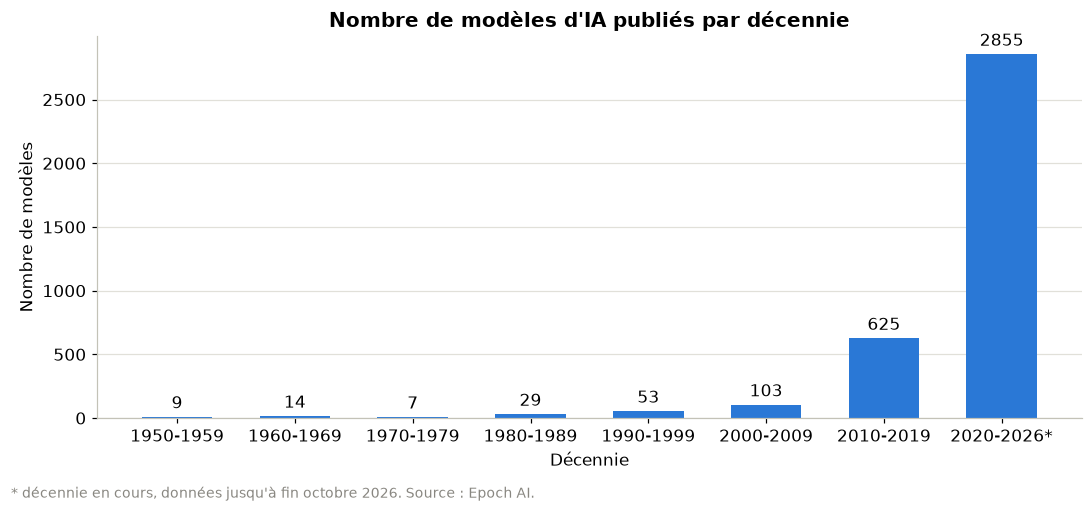

In [3]:
modeles = donnees("epoch_modeles_par_an").pivot_table(index="annee", columns="categorie", values="valeur")
modeles.index = modeles.index.astype(int)

# Graphique 1 : nombre de modèles par décennie
decennies = modeles["Tous les modèles"].groupby(modeles.index // 10 * 10).sum()
etiquettes = [f"{d}-{d + 9}" if d < 2020 else "2020-2026*" for d in decennies.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
barres = ax.bar(etiquettes, decennies.values, color=BLEU, width=0.6)
ax.bar_label(barres, fmt="%d", padding=3)
ax.set_title("Nombre de modèles d'IA publiés par décennie")
ax.set_xlabel("Décennie")
ax.set_ylabel("Nombre de modèles")
ax.grid(axis="x", visible=False)
fig.text(0.01, -0.02, "* décennie en cours, données jusqu'à fin octobre 2026. Source : Epoch AI.",
         fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

In [4]:
# Graphique 2 (interactif) : évolution année par année depuis 2000
recent = modeles.loc[2000:].reset_index().melt(id_vars="annee", var_name="Série", value_name="Nombre")
fig = px.line(recent, x="annee", y="Nombre", color="Série", markers=True,
              color_discrete_sequence=[ORANGE, BLEU],
              title="Modèles d'IA publiés chaque année depuis 2000",
              labels={"annee": "Année", "Nombre": "Nombre de modèles"})
# 2025-2026 : la base est complétée avec retard, la baisse n'est pas forcément réelle
fig.add_vrect(x0=2024.5, x1=2026.5, fillcolor="#e1e0d9", opacity=0.5, line_width=0,
              annotation_text="données<br>incomplètes", annotation_position="top")
fig.update_layout(template="simple_white", hovermode="x unified", legend_title_text="")
fig.update_yaxes(range=[0, 1150])  # de la place pour l'étiquette au-dessus de la courbe
fig.show()

In [5]:
# Chiffres clés cités ci-dessous
tous = modeles["Tous les modèles"]
print("Premier modèle recensé :", tous.index.min())
print("Modèles recensés avant 1960 :", int(tous.loc[:1959].sum()))
print("Total des modèles datés :", int(tous.sum()))
print(f"Publiés depuis 2020 : {int(tous.loc[2020:].sum())} ({tous.loc[2020:].sum() / tous.sum():.0%})")
print("Année record :", tous.idxmax(), "avec", int(tous.max()), "modèles")
print("2025 :", int(tous[2025]), "| 2026 (jusqu'à octobre) :", int(tous[2026]))

Premier modèle recensé : 1950
Modèles recensés avant 1960 : 9
Total des modèles datés : 3695
Publiés depuis 2020 : 2855 (77%)
Année record : 2024 avec 940 modèles
2025 : 591 | 2026 (jusqu'à octobre) : 230


**Ce qu'on observe**
- L'IA n'est pas récente : les premiers modèles datent de **1950** (9 modèles recensés dans les années 1950).
- L'essor est très récent : sur 3 695 modèles datés, **2 855 (77 %) ont été publiés depuis 2020**.
- Le record est atteint en **2024 (940 modèles)** ; la baisse apparente de 2025 (591) est à prendre avec prudence, la base étant complétée avec retard.

## 2. Quels domaines et quels secteurs utilisent le plus l'IA ?

On croise deux regards : les **domaines techniques** des modèles (Epoch AI) et la part
d'**entreprises européennes** qui utilisent l'IA dans chaque secteur (Eurostat).

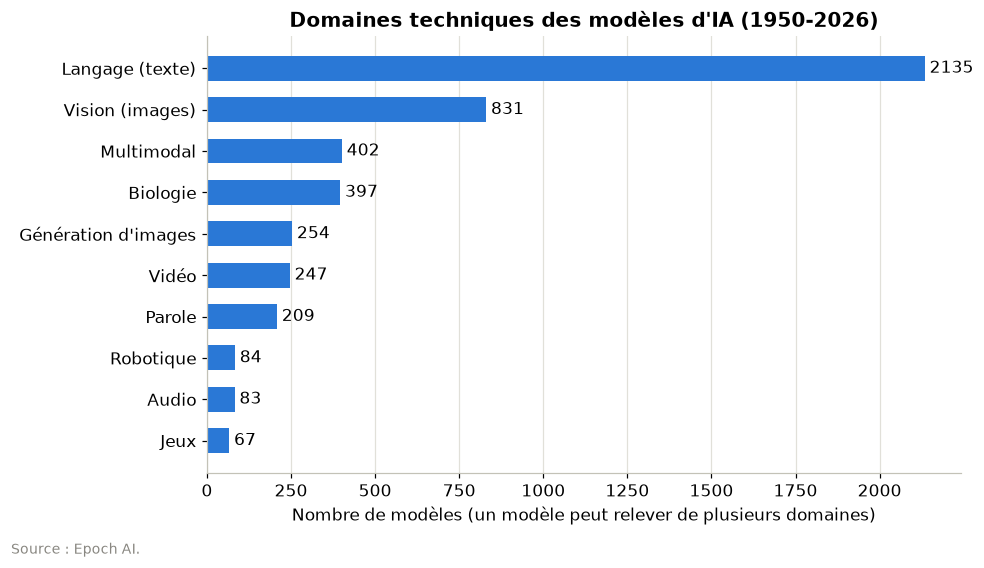

Langage : 2135 modèles, soit 58% des modèles


In [6]:
# Graphique 1 : les 10 domaines techniques les plus fréquents (toutes années)
domaines = donnees("epoch_domaines").groupby("categorie")["valeur"].sum().sort_values()
top10 = domaines.tail(10)

fig, ax = plt.subplots(figsize=(9, 5))
barres = ax.barh(top10.index, top10.values, color=BLEU, height=0.6)
ax.bar_label(barres, fmt="%d", padding=3)
ax.set_title("Domaines techniques des modèles d'IA (1950-2026)")
ax.set_xlabel("Nombre de modèles (un modèle peut relever de plusieurs domaines)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, "Source : Epoch AI.", fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

n_modeles = int(donnees("epoch_modeles_par_an").query("categorie == 'Tous les modèles'")["valeur"].sum())
print(f"Langage : {int(domaines['Langage (texte)'])} modèles, soit {domaines['Langage (texte)'] / n_modeles:.0%} des modèles")

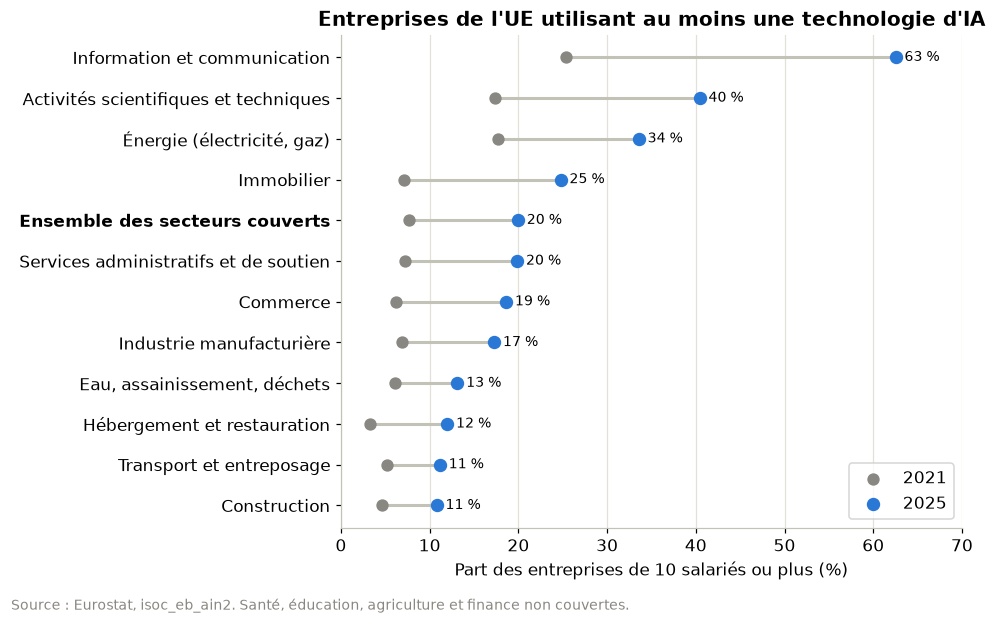

In [7]:
# Graphique 2 : part des entreprises de l'UE qui utilisent l'IA, par secteur (2021 -> 2025)
eu = donnees("eurostat_ia_secteur").query("sous_categorie == 'UE à 27'")
secteurs = eu.pivot_table(index="categorie", columns="annee", values="valeur").sort_values(2025)

fig, ax = plt.subplots(figsize=(9, 5.5))
y = range(len(secteurs))
ax.hlines(y, secteurs[2021], secteurs[2025], color="#c3c2b7", linewidth=2)
ax.scatter(secteurs[2021], y, color=GRIS, s=50, label="2021", zorder=3)
ax.scatter(secteurs[2025], y, color=BLEU, s=60, label="2025", zorder=3)
for i, v in enumerate(secteurs[2025]):
    ax.text(v + 1, i, f"{v:.0f} %", va="center", fontsize=9)
ax.set_yticks(list(y), secteurs.index)
labels = ax.get_yticklabels()
for lab in labels:  # mettre en gras la moyenne
    if lab.get_text().startswith("Ensemble"):
        lab.set_fontweight("bold")
ax.set_xlim(0, 70)
ax.set_title("Entreprises de l'UE utilisant au moins une technologie d'IA")
ax.set_xlabel("Part des entreprises de 10 salariés ou plus (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.text(0.01, -0.02, "Source : Eurostat, isoc_eb_ain2. Santé, éducation, agriculture et finance non couvertes.",
         fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

In [8]:
# Complément : dans quel secteur travaillent les répondants du Kaggle Survey ?
kag = donnees("kaggle_secteurs").dropna(subset=["valeur"])
tableau = kag.pivot_table(index="categorie", columns="annee", values="valeur").sort_values(2022, ascending=False)
print("Part des répondants en emploi, par secteur (%) – questions absentes en 2019 et 2020")
tableau.head(8).round(1)

Part des répondants en emploi, par secteur (%) – questions absentes en 2019 et 2020


annee,2017,2018,2021,2022
categorie,,,,
Informatique et technologie,21.0,32.8,25.0,25.5
Enseignement et recherche,15.3,16.1,19.7,15.9
Finance et comptabilité,10.7,8.4,8.9,8.8
Autre,18.0,5.5,7.0,8.2
Industrie manufacturière,3.8,3.3,5.3,6.2
Santé et pharmacie,1.7,4.4,4.8,5.6
Administration publique,5.2,3.7,4.4,5.5
Services Internet,6.8,7.2,5.3,5.1


**Ce qu'on observe**
- Le **langage** (texte, chatbots, traduction) domine largement : il concerne 2 135 modèles, soit 58 % des modèles recensés, loin devant la vision (831).
- En entreprise, l'**information-communication** est en tête (63 % des entreprises de l'UE en 2025), contre 20 % en moyenne et 11 % dans le transport ou la construction.
- L'usage a progressé partout entre 2021 et 2025 ; dans le Kaggle Survey, l'informatique (25,5 %) et l'enseignement-recherche (15,9 %) emploient le plus de répondants en 2022.

## Zoom géographique : où se trouve l'IA ?

Deux cartes interactives (survolez un pays pour voir son chiffre) : où sont **créés** les
modèles d'IA dans le monde (Epoch AI), et où les entreprises européennes les **utilisent** (Eurostat).

In [9]:
# Carte 1 : nombre de modèles d'IA créés par pays (1950-2026)
pays = donnees("epoch_pays").groupby(["code_pays", "categorie"])["valeur"].sum().reset_index()

# Les écarts sont énormes (de 1 à plus de 2 700) : on regroupe les pays en classes
classes = ["1", "2 à 9", "10 à 49", "50 à 199", "200 à 999", "1 000 et plus"]
pays["Nombre de modèles"] = pd.cut(pays["valeur"], [0, 1, 9, 49, 199, 999, float("inf")], labels=classes)
bleus = ["#b7d3f6", "#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

fig = px.choropleth(pays, locations="code_pays", color="Nombre de modèles",
                    hover_name="categorie", hover_data={"valeur": True, "code_pays": False},
                    category_orders={"Nombre de modèles": classes},
                    color_discrete_sequence=bleus,
                    labels={"valeur": "Modèles"},
                    title="Pays des organisations qui ont créé des modèles d'IA (1950-2026)")
fig.update_geos(projection_type="natural earth", resolution=50, showframe=False,
                showcountries=True, countrycolor="white", landcolor="#e1e0d9",
                lataxis_range=[-58, 85])  # sans l'Antarctique
fig.update_traces(marker_line_color="white", marker_line_width=0.5)
fig.add_annotation(text="En gris : aucun modèle recensé. Source : Epoch AI.", showarrow=False,
                   x=0, y=-0.02, xref="paper", yref="paper", font=dict(size=11, color=GRIS))
fig.update_layout(template="simple_white", margin=dict(l=0, r=0, t=50, b=20), height=480)
fig.show()

top = pays.sort_values("valeur", ascending=False).set_index("categorie")["valeur"]
print("Les 5 premiers pays :", ", ".join(f"{p} ({int(v)})" for p, v in top.head(5).items()))
print("Pays représentés :", len(top))
print("Océanie :", ", ".join(f"{p} ({int(top[p])})" for p in ["Australie", "Nouvelle-Zélande"]))

Les 5 premiers pays : États-Unis (2758), Chine (1308), Royaume-Uni (294), Canada (244), France (192)
Pays représentés : 49
Océanie : Australie (28), Nouvelle-Zélande (2)


In [10]:
# Carte 2 : part des entreprises utilisant l'IA en 2025, par pays européen
eu_pays = donnees("eurostat_ia_pays").pivot_table(index=["code_pays", "categorie"],
                                                  columns="annee", values="valeur").reset_index()
eu_pays = eu_pays.dropna(subset=[2025]).rename(columns={2021: "En 2021 (%)", 2025: "En 2025 (%)"})

fig = px.choropleth(eu_pays, locations="code_pays", color="En 2025 (%)",
                    hover_name="categorie",
                    hover_data={"En 2025 (%)": ":.1f", "En 2021 (%)": ":.1f", "code_pays": False},
                    color_continuous_scale=["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"],
                    range_color=[0, 45],
                    title="Entreprises utilisant au moins une technologie d'IA en 2025 (%)")
fig.update_geos(fitbounds="locations", resolution=50, showframe=False,
                showcountries=True, countrycolor="white", landcolor="#e1e0d9")
fig.update_traces(marker_line_color="white", marker_line_width=0.5)
fig.add_annotation(text="En gris : pays non couvert par l'enquête (Royaume-Uni, Suisse, Islande…). Source : Eurostat.",
                   showarrow=False, x=0, y=-0.02, xref="paper", yref="paper", font=dict(size=11, color=GRIS))
fig.update_layout(template="simple_white", margin=dict(l=0, r=0, t=50, b=20), height=520,
                  coloraxis_colorbar=dict(title="% des<br>entreprises"))
fig.show()

classement = eu_pays.set_index("categorie")["En 2025 (%)"].sort_values(ascending=False)
print("Les 3 premiers :", ", ".join(f"{p} {v:.0f} %" for p, v in classement.head(3).items()))
print("Les 3 derniers :", ", ".join(f"{p} {v:.1f} %" for p, v in classement.tail(3).items()))
ue = donnees("eurostat_ia_secteur").query("categorie == 'Ensemble des secteurs couverts' and sous_categorie == 'UE à 27'")
moyenne_ue = ue.set_index("annee").loc[2025, "valeur"]
print(f"France : {classement['France']:.1f} % (moyenne UE à 27 : {moyenne_ue:.1f} %)")

Les 3 premiers : Danemark 42 %, Finlande 38 %, Suède 35 %
Les 3 derniers : Pologne 8.4 %, Turquie 7.4 %, Roumanie 5.2 %
France : 18.2 % (moyenne UE à 27 : 19.9 %)


**Ce qu'on observe**
- La création de modèles est très concentrée : les **États-Unis (2 758)** et la **Chine (1 308)** devancent de loin le Royaume-Uni (294) ; la France est 5e (192).
- En Europe, l'usage de l'IA est le plus fort dans les **pays nordiques** (Danemark 42 %, Finlande 38 %, Suède 35 %) et le plus faible en Roumanie (5 %) ; la France (18 %) est un peu sous la moyenne de l'UE (20 %).
- Le Pacifique est quasi absent : en Océanie, seules l'Australie (28 modèles) et la Nouvelle-Zélande (2) apparaissent, et aucune source ne couvre la Polynésie française.

## 3. Quels types de modèles sont les plus utilisés ?

Le **Kaggle Survey** (2017-2022) demande aux praticiens quels algorithmes ils utilisent
régulièrement ; **Eurostat** indique quelles technologies d'IA les entreprises emploient.

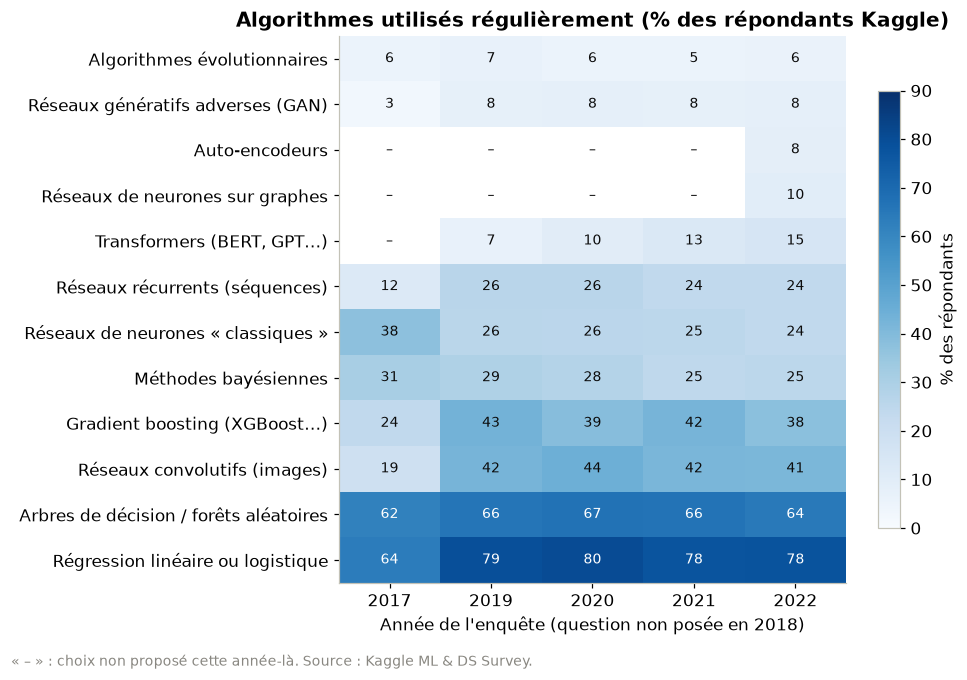

In [11]:
# Graphique 1 : part des répondants Kaggle utilisant chaque famille d'algorithmes
algos = donnees("kaggle_algorithmes").dropna(subset=["valeur"])
carte = algos.pivot_table(index="categorie", columns="annee", values="valeur").sort_values(2022)

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(carte.values, cmap="Blues", aspect="auto", vmin=0, vmax=90)
for i in range(carte.shape[0]):
    for j in range(carte.shape[1]):
        v = carte.values[i, j]
        texte = "–" if pd.isna(v) else f"{v:.0f}"
        ax.text(j, i, texte, ha="center", va="center", fontsize=9,
                color="white" if (not pd.isna(v) and v > 50) else "#0b0b0b")
ax.set_xticks(range(carte.shape[1]), carte.columns)
ax.set_yticks(range(carte.shape[0]), carte.index)
ax.grid(False)
ax.set_title("Algorithmes utilisés régulièrement (% des répondants Kaggle)")
ax.set_xlabel("Année de l'enquête (question non posée en 2018)")
fig.colorbar(im, ax=ax, label="% des répondants", shrink=0.8)
fig.text(0.01, -0.02, "« – » : choix non proposé cette année-là. Source : Kaggle ML & DS Survey.",
         fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

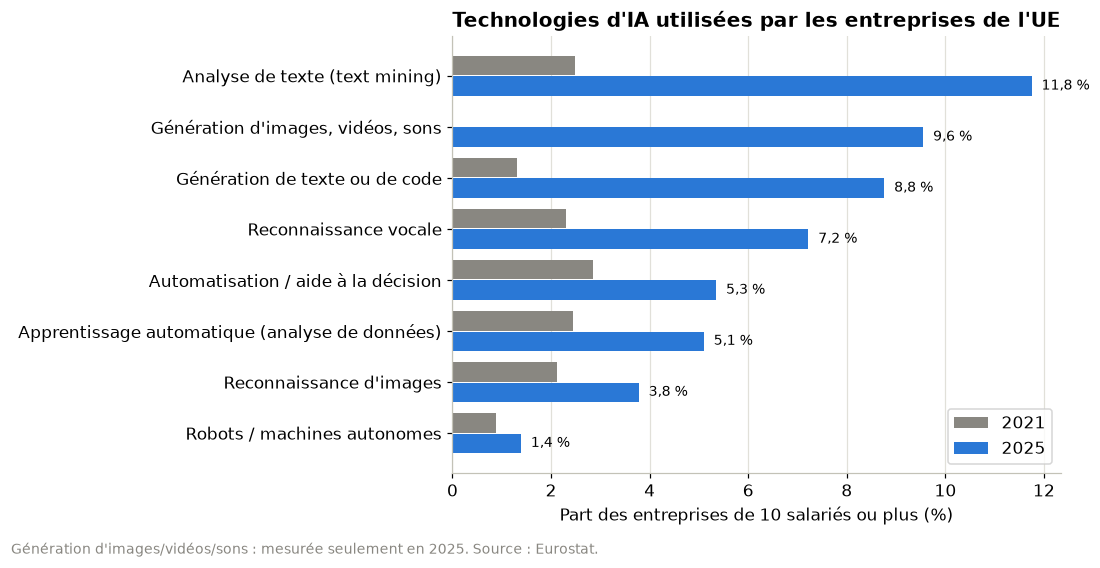

In [12]:
# Graphique 2 : technologies d'IA utilisées par les entreprises de l'UE
tech = donnees("eurostat_ia_technologie").query("sous_categorie == 'UE à 27'")
tech = tech.pivot_table(index="categorie", columns="annee", values="valeur").sort_values(2025)

fig, ax = plt.subplots(figsize=(10, 5))
y = range(len(tech))
ax.barh([i + 0.2 for i in y], tech[2021], height=0.38, color=GRIS, label="2021")
ax.barh([i - 0.2 for i in y], tech[2025], height=0.38, color=BLEU, label="2025")
for i, v in enumerate(tech[2025]):
    ax.text(v + 0.2, i - 0.2, f"{v:.1f} %".replace(".", ","), va="center", fontsize=9)
ax.set_yticks(list(y), tech.index)
ax.set_title("Technologies d'IA utilisées par les entreprises de l'UE")
ax.set_xlabel("Part des entreprises de 10 salariés ou plus (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.text(0.01, -0.02, "Génération d'images/vidéos/sons : mesurée seulement en 2025. Source : Eurostat.",
         fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

**Ce qu'on observe**
- Les méthodes **simples** dominent : en 2022, 78 % des répondants Kaggle utilisent la régression et environ deux sur trois les arbres de décision, loin devant les réseaux de neurones.
- Les **Transformers** (la technologie de ChatGPT) progressent vite : de 7 % des répondants en 2019 à 15 % en 2022.
- En entreprise, l'IA du **langage** décolle : l'analyse de texte passe de 2,5 % à 11,8 % des entreprises de l'UE entre 2021 et 2025, et la génération de texte de 1,3 % à 8,8 %.

## 4. Quels sont les points positifs et négatifs de l'IA ?

L'étude de **Vinuesa et al. (2020)** a évalué, pour chacune des 169 cibles des Objectifs de
développement durable (ODD), si l'IA peut aider à l'atteindre (levier) ou la freiner.
Les **incidents** recensés dans la presse illustrent les dérives concrètes.

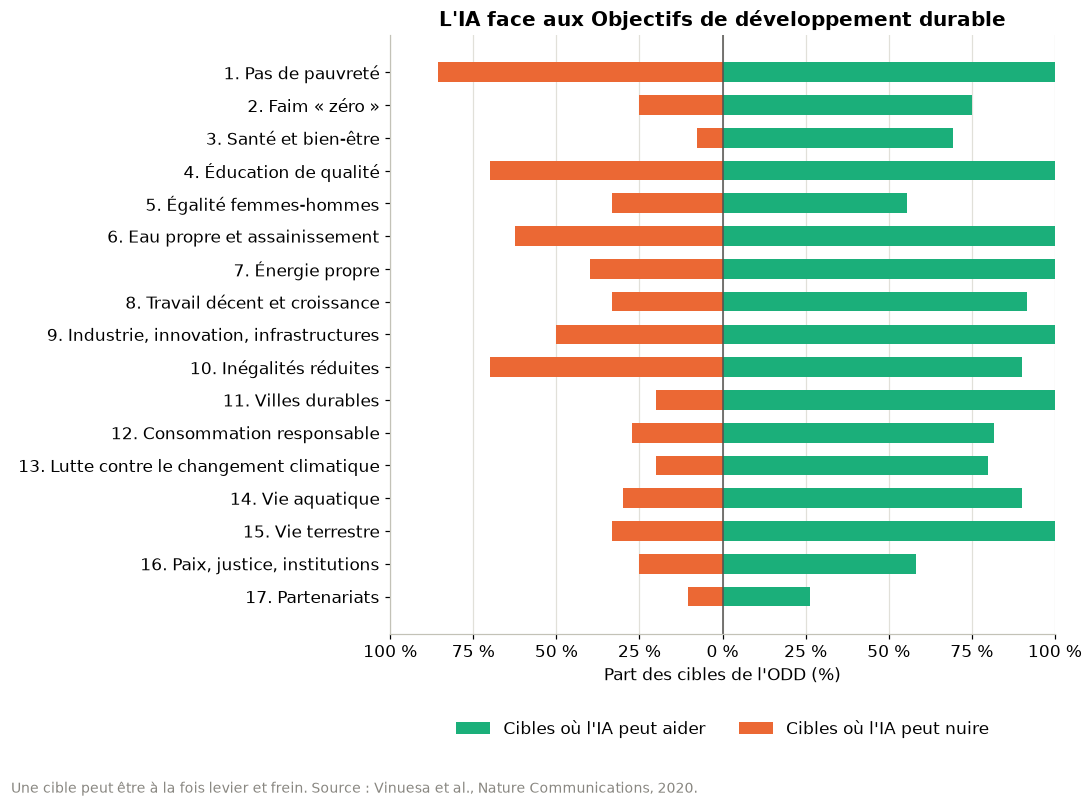

Sur 169 cibles : levier pour 134 (79%), frein pour 59 (35%)
ODD où l'IA peut le plus nuire (part des cibles) :
categorie
1. Pas de pauvreté         86.0
10. Inégalités réduites    70.0
4. Éducation de qualité    70.0


In [13]:
# Graphique 1 : pour chaque ODD, part des cibles où l'IA est un levier ou un frein
odd = donnees("vinuesa_odd")
odd["part"] = 100 * odd["valeur"] / odd["base"]
odd["num"] = odd["categorie"].str.split(".").str[0].astype(int)
p = odd.pivot_table(index=["num", "categorie"], columns="sous_categorie", values="part")
p = p.sort_index(ascending=False).droplevel("num")
levier, frein = "L'IA peut aider (levier)", "L'IA peut nuire (frein)"

fig, ax = plt.subplots(figsize=(10, 7))
y = range(len(p))
ax.barh(y, p[levier], color=VERT_EAU, height=0.6, label="Cibles où l'IA peut aider")
ax.barh(y, -p[frein], color=ORANGE, height=0.6, label="Cibles où l'IA peut nuire")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(list(y), p.index)
ax.set_xlim(-100, 100)
ax.set_xticks(range(-100, 101, 25), [f"{abs(t)} %" for t in range(-100, 101, 25)])
ax.set_title("L'IA face aux Objectifs de développement durable")
ax.set_xlabel("Part des cibles de l'ODD (%)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
fig.text(0.01, -0.04, "Une cible peut être à la fois levier et frein. Source : Vinuesa et al., Nature Communications, 2020.",
         fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

total = odd.groupby("sous_categorie")["valeur"].sum()
n = odd.drop_duplicates("categorie")["base"].sum()
print(f"Sur {int(n)} cibles : levier pour {int(total[levier])} ({total[levier] / n:.0%}), "
      f"frein pour {int(total[frein])} ({total[frein] / n:.0%})")
print("ODD où l'IA peut le plus nuire (part des cibles) :")
print(p[frein].sort_values(ascending=False).head(3).round(0).to_string())

In [14]:
# Graphique 2 (interactif) : incidents et controverses liés à l'IA signalés chaque année
inc = donnees("owid_incidents")
fig = px.bar(inc, x="annee", y="valeur", color_discrete_sequence=[ORANGE],
             title="Incidents et controverses liés à l'IA signalés dans le monde",
             labels={"annee": "Année", "valeur": "Nombre d'incidents signalés"})
fig.update_layout(template="simple_white")
fig.update_xaxes(dtick=1)
fig.show()

i = inc.set_index("annee")["valeur"]
print(f"{int(i[2012])} incidents en 2012, {int(i[2024])} en 2024 (x{i[2024] / i[2012]:.0f})")

8 incidents en 2012, 233 en 2024 (x29)


In [15]:
# Complément : pourquoi certaines entreprises renoncent-elles à l'IA ?
freins = donnees("eurostat_ia_freins").query("annee == 2025")
print("Raisons citées en 2025 par les entreprises de l'UE ayant envisagé l'IA sans l'utiliser (%)")
freins.set_index("categorie")["valeur"].sort_values(ascending=False).round(0).to_frame("% des entreprises")

Raisons citées en 2025 par les entreprises de l'UE ayant envisagé l'IA sans l'utiliser (%)


,% des entreprises
categorie,
Manque de compétences,70.0
Flou juridique,54.0
Protection des données / vie privée,53.0
Données insuffisantes ou de mauvaise qualité,44.0
Incompatibilité avec les systèmes existants,42.0
Coûts trop élevés,38.0
Considérations éthiques,25.0
IA jugée inutile pour l'entreprise,18.0


**Ce qu'on observe**
- D'après les experts, l'IA peut **aider** à atteindre 134 des 169 cibles des ODD (79 %), mais peut en **freiner** 59 (35 %).
- Les risques sont les plus forts pour les ODD sociaux : pauvreté (6 cibles sur 7), inégalités et éducation (7 sur 10).
- Les incidents signalés sont passés de **8 en 2012 à 233 en 2024** (environ 29 fois plus), et les entreprises qui renoncent citent d'abord le manque de compétences (70 %), le flou juridique (54 %) et la vie privée (53 %).

## 5. Synthèse

In [16]:
synthese = pd.DataFrame([
    ["1. Depuis quand ?", "Depuis 1950, mais 77 % des modèles datent de 2020 ou après", "Epoch AI"],
    ["2. Quels domaines / secteurs ?", "Langage d'abord ; information-communication : 63 % des entreprises de l'UE en 2025", "Epoch AI, Eurostat"],
    ["Où ?", "Création concentrée aux États-Unis et en Chine ; usage plus fort dans les pays nordiques", "Epoch AI, Eurostat"],
    ["3. Quels modèles ?", "Régression et arbres de décision dominent ; Transformers en forte hausse", "Kaggle Survey, Eurostat"],
    ["4. Positif / négatif ?", "Levier pour 79 % des cibles ODD, frein pour 35 % ; incidents en forte hausse", "Vinuesa 2020, OWID/AIID"],
], columns=["Question", "Réponse en une ligne", "Sources"])
synthese.set_index("Question")

,Réponse en une ligne,Sources
Question,,
1. Depuis quand ?,"Depuis 1950, mais 77 % des modèles datent de 2020 ou après",Epoch AI
2. Quels domaines / secteurs ?,Langage d'abord ; information-communication : 63 % des entreprises de l'UE en 2025,"Epoch AI, Eurostat"
Où ?,Création concentrée aux États-Unis et en Chine ; usage plus fort dans les pays nordiques,"Epoch AI, Eurostat"
3. Quels modèles ?,Régression et arbres de décision dominent ; Transformers en forte hausse,"Kaggle Survey, Eurostat"
4. Positif / négatif ?,"Levier pour 79 % des cibles ODD, frein pour 35 % ; incidents en forte hausse","Vinuesa 2020, OWID/AIID"


### Points positifs
- **Un outil au service des ODD** : selon les experts, l'IA peut aider pour 79 % des cibles,
  notamment l'environnement (vie terrestre, villes durables, vie aquatique).
- **Une technologie qui se diffuse** : 20 % des entreprises de l'UE l'utilisent en 2025, contre 8 % en 2021.
- **Des méthodes accessibles** : les algorithmes les plus utilisés (régression, arbres de décision)
  sont simples, interprétables et peu coûteux à faire tourner.

### Points négatifs
- **Des risques sociaux** : l'IA peut freiner 35 % des cibles des ODD, surtout celles liées à la
  pauvreté, aux inégalités et à l'éducation.
- **Des incidents en forte hausse** : 233 incidents signalés en 2024, soit environ 29 fois plus qu'en 2012.
- **Des obstacles à l'adoption** : manque de compétences, flou juridique et protection de la vie privée.
- **Une concentration** : l'activité reste dominée par le langage et par le secteur numérique.

## 6. Limites des données

Il faut garder un regard critique sur ces chiffres :

- **Epoch AI** décrit des **domaines techniques** (langage, vision…), pas des secteurs
  économiques. La base est complétée avec retard : les années 2025-2026 sont sous-estimées.
  Sur la carte, le pays est celui de l'**organisation créatrice** (pas celui des utilisateurs) ;
  un modèle créé par plusieurs pays est compté dans chacun, et les organisations
  « multinationales » ne sont pas placées. Les petits territoires (Singapour, Hong Kong)
  sont à peine visibles sur la carte.
- **Eurostat** ne couvre que l'**Union européenne** (pas la Polynésie française) et les entreprises
  de 10 salariés ou plus ; il **exclut la santé, l'éducation, l'agriculture et la finance**. Pas d'enquête en 2022.
- Le **Kaggle Survey** s'arrête en **2022** et reflète la **communauté Kaggle** (plutôt jeune,
  technique, volontaire), pas l'ensemble des professionnels. Les questions changent d'une année
  à l'autre : algorithmes non demandés en 2018, secteur non demandé en 2019 et 2020.
- Les **incidents** sont recensés à partir d'articles de **presse** : ils sont **sous-déclarés**,
  et leur hausse reflète aussi une attention médiatique croissante.
- **Vinuesa et al.** est un **avis d'experts de 2020**, fondé sur la littérature, antérieur à
  l'essor de l'IA générative.

## 7. Sources et licences

Toutes les données ont été téléchargées le **12 novembre 2026**.

| Source | Données | Licence |
|---|---|---|
| Epoch AI, *Data on AI Models* – [epoch.ai/data/ai-models](https://epoch.ai/data/ai-models) | Base complète et modèles notables | CC BY 4.0 |
| Kaggle, *ML & DS Survey* 2017 et 2018 – [kaggle.com/datasets/kaggle](https://www.kaggle.com/datasets/kaggle/kaggle-survey-2018) | Réponses à l'enquête | 2017 : ODbL 1.0 ; 2018 : CC BY-SA 4.0 |
| Kaggle, *Kaggle Survey* 2019 à 2022 – [kaggle.com/competitions](https://www.kaggle.com/competitions/kaggle-survey-2022) | Réponses à l'enquête | Règles des compétitions Kaggle |
| Eurostat, *isoc_eb_ain2* – [ec.europa.eu/eurostat](https://ec.europa.eu/eurostat/databrowser/view/isoc_eb_ain2/default/table) | Usage de l'IA par les entreprises | Réutilisation libre avec mention de la source |
| Our World in Data / AI Incident Database via AI Index 2025 – [ourworldindata.org](https://ourworldindata.org/artificial-intelligence) | Incidents et controverses par an | OWID : CC BY 4.0 ; AI Index : CC BY-ND 4.0 |
| Vinuesa R. et al., *The role of artificial intelligence in achieving the Sustainable Development Goals*, Nature Communications 11, 233 (2020) – [doi:10.1038/s41467-019-14108-y](https://doi.org/10.1038/s41467-019-14108-y) | Supplementary Data 1 | CC BY 4.0 |

*Note : le graphique OWID d'origine a été retiré du site ; la même série a été récupérée via
l'API officielle d'OWID (indicateur 1025675).*